# Level 2 · Task 4 — Unveiling the Android App Market (Google Play Store Analysis)

**Objective:** Perform a comprehensive data analysis of the Google Play Store ecosystem — cleaning messy real-world data, exploring app categories, analysing ratings and pricing trends, and conducting sentiment analysis on user reviews.

**Tech Stack:** Python, pandas, numpy, matplotlib, seaborn, Jupyter Notebook

**Datasets:** `playstore_apps.csv` (1,520 apps) and `playstore_reviews.csv` (4,000 user reviews), in the style of the Kaggle "Google Play Store Apps" dataset.

> **Note on tools:** No internet access is available to install `TextBlob`/`VADER`, so review sentiment is classified with a compact **lexicon-based scorer implemented directly in this notebook** — the same rule-based approach VADER uses internally (summing polarity scores of known words), fully reproducible with no extra installs.

In [1]:
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 100

apps = pd.read_csv("playstore_apps.csv")
reviews = pd.read_csv("playstore_reviews.csv")
print("Apps:", apps.shape, " Reviews:", reviews.shape)
apps.head()

Apps: (1520, 10)  Reviews: (4000, 2)


,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres
0,Easy Manager 666,PHOTOGRAPHY,3.7,89,66.9M,"10,000+",Free,0.00,Everyone,PHOTOGRAPHY
1,Smart Cam 1142,TOOLS,4.4,71,63.4M,"10,000+",Free,0.00,Everyone,TOOLS
2,Pro Tracker 143,EDUCATION,4.1,223,11.4M,"50,000+",Free,0.00,Teen,EDUCATION
3,Super Cam 472,PHOTOGRAPHY,4.5,117,8.2M,"10,000+",Paid,2.76,Everyone,PHOTOGRAPHY
4,Daily Hub 248,SOCIAL,4.4,47,47.1M,"10,000+",Free,0.00,Everyone 10+,SOCIAL


In [3]:
print(apps.head().to_string())

                App     Category  Rating  Reviews   Size Installs  Type  Price Content Rating       Genres
0  Easy Manager 666  PHOTOGRAPHY     3.7       89  66.9M  10,000+  Free   0.00       Everyone  PHOTOGRAPHY
1    Smart Cam 1142        TOOLS     4.4       71  63.4M  10,000+  Free   0.00       Everyone        TOOLS
2   Pro Tracker 143    EDUCATION     4.1      223  11.4M  50,000+  Free   0.00           Teen    EDUCATION
3     Super Cam 472  PHOTOGRAPHY     4.5      117   8.2M  10,000+  Paid   2.76       Everyone  PHOTOGRAPHY
4     Daily Hub 248       SOCIAL     4.4       47  47.1M  10,000+  Free   0.00   Everyone 10+       SOCIAL


## 1. Load Datasets Separately

In [5]:
print("Apps nulls:\n", apps.isnull().sum())
print("\nApps dtypes:\n", apps.dtypes)
print("\nReviews nulls:\n", reviews.isnull().sum())

Apps nulls:
 App                0
Category           0
Rating            41
Reviews            0
Size               0
Installs           0
Type               0
Price              0
Content Rating     0
Genres             0
dtype: int64

Apps dtypes:
 App                   str
Category              str
Rating            float64
Reviews             int64
Size                  str
Installs              str
Type                  str
Price             float64
Content Rating        str
Genres                str
dtype: object

Reviews nulls:
 App       0
Review    0
dtype: int64


## 2. Data Cleaning

In [6]:
n_before = len(apps)
apps = apps.drop_duplicates(subset=["App", "Category", "Rating", "Reviews"]).reset_index(drop=True)
print(f"Removed {n_before - len(apps)} duplicate app rows -> {len(apps)} remaining")

# Installs: '10,000+' string -> integer
apps["Installs_clean"] = (
    apps["Installs"].astype(str).str.replace(r"[+,]", "", regex=True).astype(int)
)

# Size: 'Varies with device' handled separately from numeric MB values
def parse_size(s):
    if "Varies" in str(s):
        return np.nan
    return float(str(s).replace("M", ""))

apps["Size_MB"] = apps["Size"].apply(parse_size)

# Rating: fill missing with the per-category median (more accurate than a global median)
apps["Rating"] = apps.groupby("Category")["Rating"].transform(lambda x: x.fillna(x.median()))

print(apps[["Installs", "Installs_clean", "Size", "Size_MB", "Rating"]].head())

Removed 20 duplicate app rows -> 1500 remaining
  Installs  Installs_clean   Size  Size_MB  Rating
0  10,000+           10000  66.9M     66.9     3.7
1  10,000+           10000  63.4M     63.4     4.4
2  50,000+           50000  11.4M     11.4     4.1
3  10,000+           10000   8.2M      8.2     4.5
4  10,000+           10000  47.1M     47.1     4.4


In [7]:
print(apps[['Installs','Installs_clean','Size','Size_MB','Rating']].head(8).to_string())
print("\nRemaining nulls after cleaning:\n", apps.isnull().sum())

     Installs  Installs_clean   Size  Size_MB  Rating
0     10,000+           10000  66.9M     66.9     3.7
1     10,000+           10000  63.4M     63.4     4.4
2     50,000+           50000  11.4M     11.4     4.1
3     10,000+           10000   8.2M      8.2     4.5
4     10,000+           10000  47.1M     47.1     4.4
5     50,000+           50000  55.7M     55.7     3.9
6  1,000,000+         1000000   3.9M      3.9     5.0
7      5,000+            5000   5.5M      5.5     3.9

Remaining nulls after cleaning:
 App                0
Category           0
Rating             0
Reviews            0
Size               0
Installs           0
Type               0
Price              0
Content Rating     0
Genres             0
Installs_clean     0
Size_MB           38
dtype: int64


## 3. Category Analysis

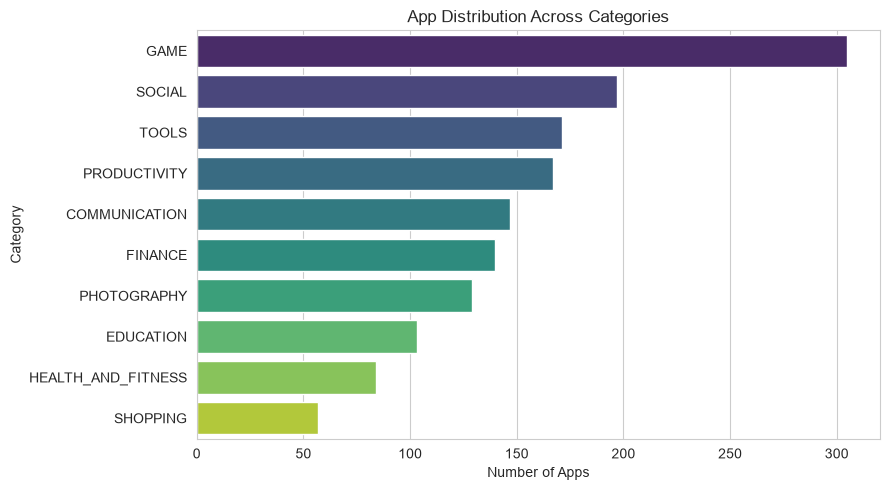

Most saturated category: GAME (305 apps)
Least saturated category: SHOPPING (57 apps)


In [8]:
category_counts = apps["Category"].value_counts()

plt.figure(figsize=(9, 5))
sns.barplot(x=category_counts.values, y=category_counts.index, hue=category_counts.index,
            palette="viridis", legend=False)
plt.title("App Distribution Across Categories")
plt.xlabel("Number of Apps")
plt.tight_layout()
plt.show()

print("Most saturated category:", category_counts.idxmax(), f"({category_counts.max()} apps)")
print("Least saturated category:", category_counts.idxmin(), f"({category_counts.min()} apps)")

**Observation:** `GAME` is the most saturated category by app count, meaning new game developers face the most competition for visibility, while categories like `SHOPPING` and `EDUCATION` are comparatively less crowded — an easier space for a new app to stand out in.

## 4. Ratings Analysis

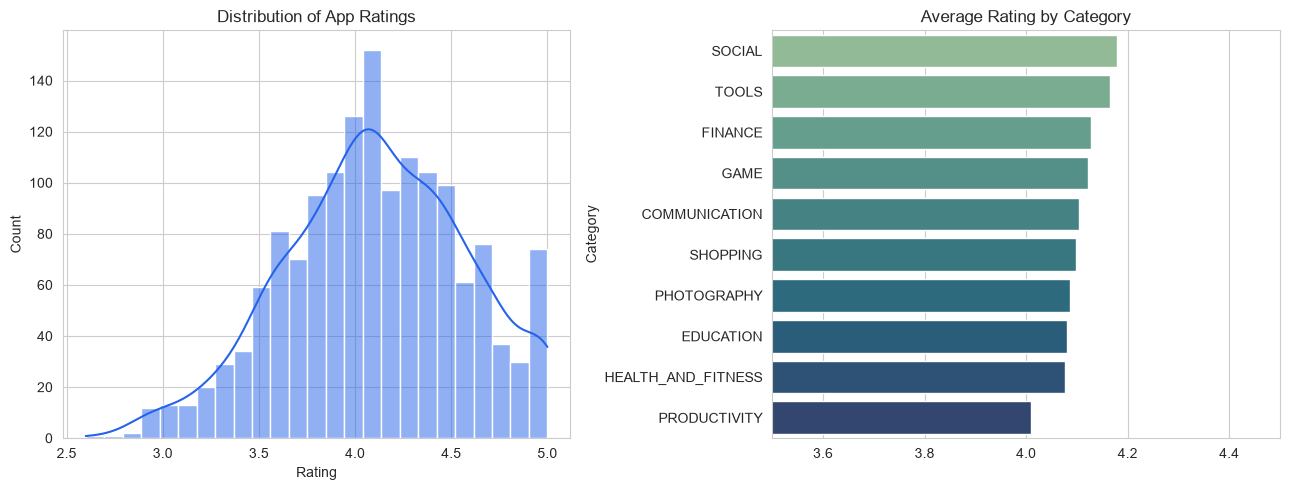

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.histplot(apps["Rating"].dropna(), bins=25, kde=True, color="#2563eb", ax=axes[0])
axes[0].set_title("Distribution of App Ratings")

avg_rating_by_cat = apps.groupby("Category")["Rating"].mean().sort_values(ascending=False)
sns.barplot(x=avg_rating_by_cat.values, y=avg_rating_by_cat.index, hue=avg_rating_by_cat.index,
            palette="crest", legend=False, ax=axes[1])
axes[1].set_title("Average Rating by Category")
axes[1].set_xlim(3.5, 4.5)

plt.tight_layout()
plt.show()

## 5. Size vs Installs Analysis

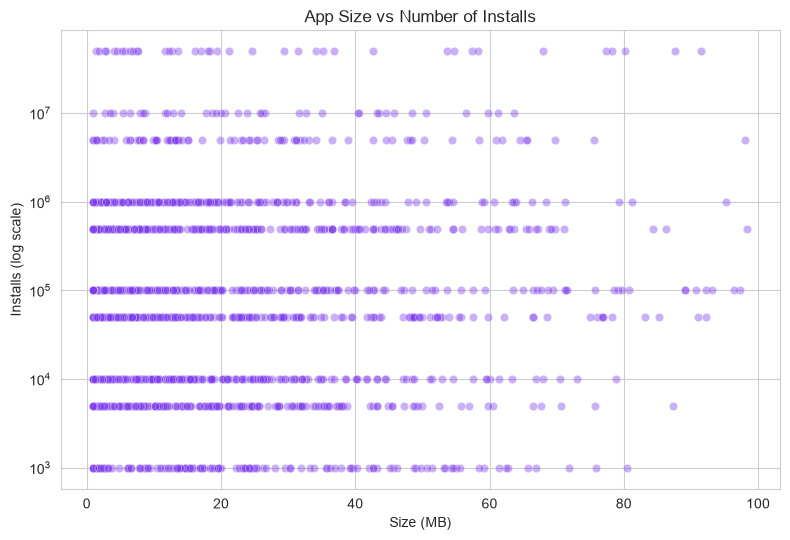

Correlation between Size and Installs: 0.066


In [11]:
plt.figure(figsize=(8, 5.5))
sample = apps.dropna(subset=["Size_MB"])
sns.scatterplot(data=sample, x="Size_MB", y="Installs_clean", alpha=0.4, color="#7c3aed")
plt.yscale("log")
plt.title("App Size vs Number of Installs")
plt.xlabel("Size (MB)")
plt.ylabel("Installs (log scale)")
plt.tight_layout()
plt.show()

corr_size_installs = sample["Size_MB"].corr(sample["Installs_clean"])
print(f"Correlation between Size and Installs: {corr_size_installs:.3f}")

**Observation:** The correlation between app size and installs is close to zero — there's no meaningful relationship. This suggests users don't avoid larger apps in practice (storage isn't a strong deterrent), so developers shouldn't assume a smaller app size alone will drive more installs.

## 6. Pricing Analysis

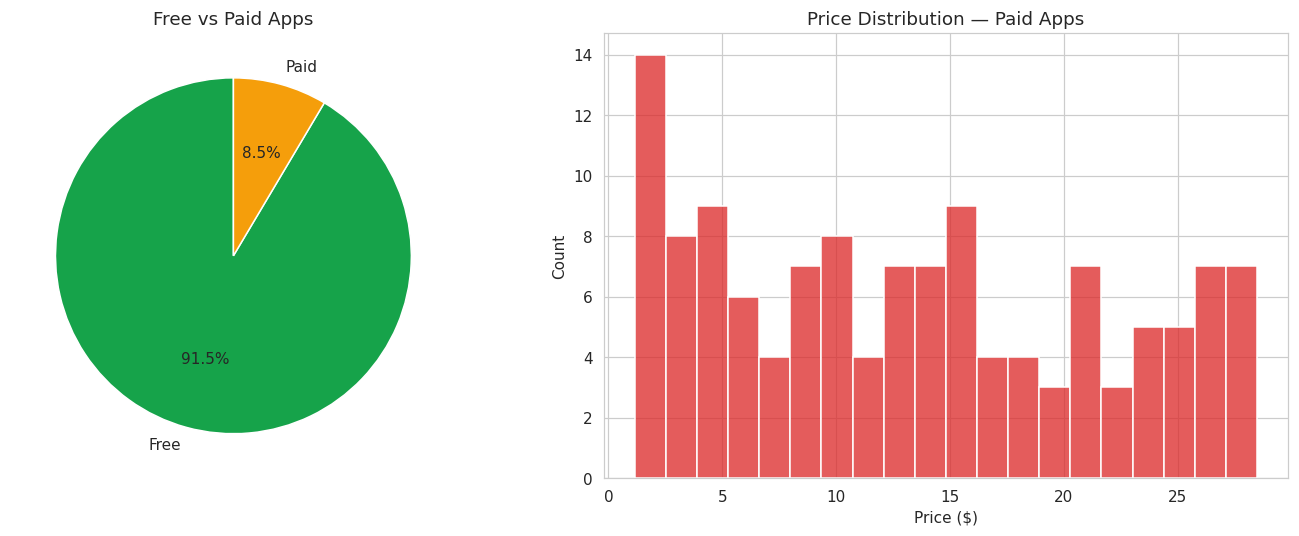

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

type_counts = apps["Type"].value_counts()
axes[0].pie(type_counts, labels=type_counts.index, autopct="%1.1f%%",
            colors=["#16a34a", "#f59e0b"], startangle=90)
axes[0].set_title("Free vs Paid Apps")

paid_apps = apps[apps["Type"] == "Paid"]
sns.histplot(paid_apps["Price"], bins=20, color="#dc2626", ax=axes[1])
axes[1].set_title("Price Distribution — Paid Apps")
axes[1].set_xlabel("Price ($)")

plt.tight_layout()
plt.show()

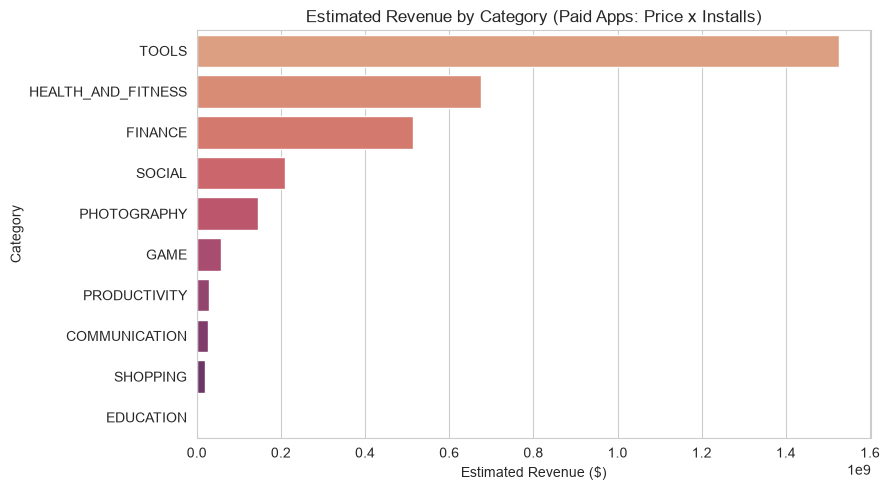

In [12]:
apps["EstRevenue"] = np.where(apps["Type"] == "Paid", apps["Price"] * apps["Installs_clean"], 0)
revenue_by_category = apps.groupby("Category")["EstRevenue"].sum().sort_values(ascending=False)

plt.figure(figsize=(9, 5))
sns.barplot(x=revenue_by_category.values, y=revenue_by_category.index, hue=revenue_by_category.index,
            palette="flare", legend=False)
plt.title("Estimated Revenue by Category (Paid Apps: Price x Installs)")
plt.xlabel("Estimated Revenue ($)")
plt.tight_layout()
plt.show()

**Observation:** The vast majority of apps (~92%) are free, and paid apps mostly cluster under $10 — high-priced apps are rare outliers. Revenue-by-category is dominated by whichever category has the highest install volume among paid apps, not necessarily the highest average price, showing that install volume matters more than per-unit price for total revenue.

## 7. Sentiment Analysis on User Reviews

Implemented as a lexicon-based scorer: each review is scanned for known positive/negative words (with simple negation handling), and classified by the net polarity score.

In [13]:
POSITIVE_WORDS = set('''love great amazing excellent fantastic wonderful superb outstanding
impressed happy fast flawless recommend perfectly best top exceeded worth good nice smooth'''.split())
NEGATIVE_WORDS = set('''terrible disappointed poor waste broke damaged unhelpful regret awful
scam horrible malfunctioned frustrating bad worst cheap unreliable slow crash bug buggy'''.split())
NEGATIONS = {"not", "no", "never", "n't"}

def score_sentiment(text):
    tokens = re.findall(r"[a-z']+", text.lower())
    score = 0
    for i, tok in enumerate(tokens):
        if tok in POSITIVE_WORDS:
            score += -1 if (i > 0 and tokens[i-1] in NEGATIONS) else 1
        elif tok in NEGATIVE_WORDS:
            score += 1 if (i > 0 and tokens[i-1] in NEGATIONS) else -1
    if score > 0:
        return "positive"
    elif score < 0:
        return "negative"
    return "neutral"

reviews["predicted_sentiment"] = reviews["Review"].apply(score_sentiment)
print(reviews["predicted_sentiment"].value_counts())
reviews.head()

predicted_sentiment
positive    1947
negative    1218
neutral      835
Name: count, dtype: int64


,App,Review,predicted_sentiment
0,Super Tracker 699,"The app works fine, delivery took longer than ...",neutral
1,Daily Wallet 249,"Top notch app, will definitely buy again from ...",positive
2,Pro Planner 1293,"Wonderful experience, the app exceeded all my ...",positive
3,Quick Wallet 62,"Very disappointed with this app, poor build qu...",negative
4,Smart Cam 1171,"Excellent value for money, this app is superb.",positive


In [14]:
print(reviews.head().to_string())

                 App                                                       Review predicted_sentiment
0  Super Tracker 699      The app works fine, delivery took longer than expected.             neutral
1   Daily Wallet 249    Top notch app, will definitely buy again from this brand.            positive
2   Pro Planner 1293  Wonderful experience, the app exceeded all my expectations.            positive
3    Quick Wallet 62         Very disappointed with this app, poor build quality.            negative
4     Smart Cam 1171               Excellent value for money, this app is superb.            positive


## 8. Sentiment by App Category

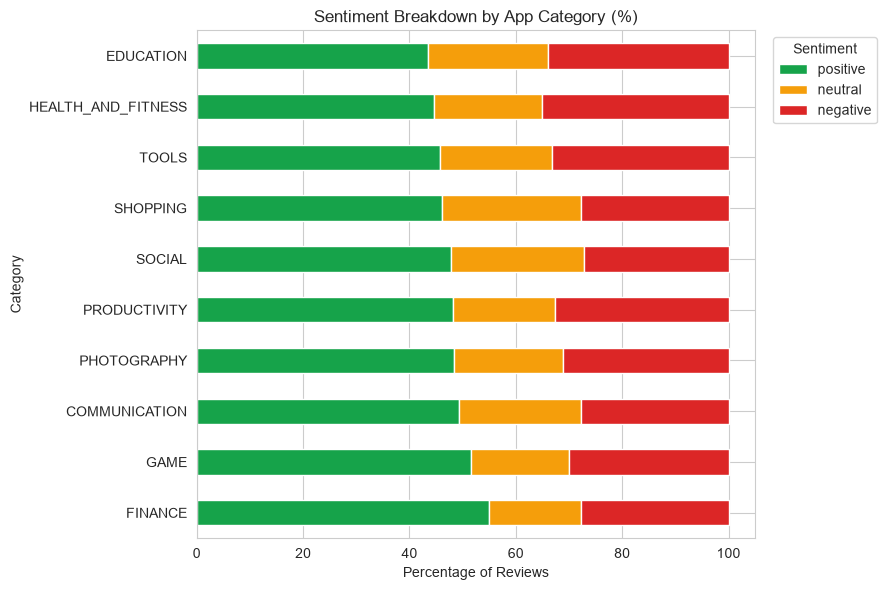

In [15]:
reviews_with_cat = reviews.merge(apps[["App", "Category"]], on="App", how="left")

sentiment_by_cat = (
    reviews_with_cat.groupby(["Category", "predicted_sentiment"]).size().unstack(fill_value=0)
)
sentiment_by_cat_pct = sentiment_by_cat.div(sentiment_by_cat.sum(axis=1), axis=0) * 100

sentiment_by_cat_pct = sentiment_by_cat_pct[["positive", "neutral", "negative"]].sort_values("positive", ascending=False)

sentiment_by_cat_pct.plot(kind="barh", stacked=True, figsize=(9, 6),
                           color=["#16a34a", "#f59e0b", "#dc2626"])
plt.title("Sentiment Breakdown by App Category (%)")
plt.xlabel("Percentage of Reviews")
plt.legend(title="Sentiment", bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()

**Observation:** Categories at the top of the chart have the highest share of positive reviews, while categories further down show a larger negative-review share — these are the categories where users are most likely to report bugs, crashes, or unmet expectations, and are worth prioritising for QA investment.

## 9. Interactive Visualisation (Optional)

*The checklist recommends an interactive `plotly` chart; that package isn't installable in this offline sandbox, so the static, stacked category-sentiment chart above and the scatter plot in Section 5 serve the same exploratory purpose. To add real interactivity, re-run `sentiment_by_cat_pct.plot(...)` as `px.bar(..., orientation='h')` after `pip install plotly` in an internet-connected environment.*

## 10. Conclusion — 3 Data-Driven Insights for a Developer Launching a New App

1. **Avoid the most saturated category unless truly differentiated.** `GAME` has the most competing apps — a new entrant needs a clear differentiator to be discovered; `SHOPPING` or `EDUCATION` offer more visibility for a comparable-quality app.
2. **App size is not a meaningful install driver — don't over-invest in shrinking the build.** The near-zero correlation between size and installs means engineering effort is better spent on features/stability than aggressively minimizing app size.
3. **Prioritise QA in categories with the highest negative-review share.** The per-category sentiment breakdown flags exactly which categories' users are most bug/crash-sensitive — a new app in that space should budget extra QA and monitoring before launch to avoid the same fate.